# TASK 3 : Part D: Encoding and PCA



## D0. Load the clean data


In [55]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load the cleaned data
df = pd.read_csv(adult_clean.csv)
print(df.shape)
df.head()

(45175, 15)


,age,workclass,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,age_group,has_capital_gain
0,39,State-gov,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,0,36-45,1
1,50,Self-emp-not-inc,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,0,46-55,0
2,38,Private,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,0,36-45,0
3,53,Private,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,0,46-55,0
4,28,Private,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,0,26-35,0


## D1. Encoding
**Your job:** choose a method for each text column and write WHY in a markdown cell.

| Column | Method | Hint |
|---|---|---|
| `sex` | label 0/1 | `.map({"Male": 1, "Female": 0})` |
| `age_group` | ordinal 0–5 | it has an order: use `.map({...})` with the 6 groups |
| `native_country` | US = 1, other = 0 | `(df[col] == "United-States").astype(int)` |
| `workclass`, `marital_status`, `occupation`, `relationship`, `race` | one-hot | `pd.get_dummies(df, columns=[...], dtype=int)` |



In [56]:
enc = df.copy()
print("Columns before encoding:", enc.shape[1])

# 1. sex -> 0/1
enc["sex"] = enc["sex"].map({"Male": 1, "Female": 0})

# 2. age_group -> 0..5 (keep the order)
age_map = {"17-25": 0, "26-35": 1, "36-45": 2, "46-55": 3, "56-65": 4, "66+": 5}
enc["age_group"] = enc["age_group"].map(age_map)

# 3. native_country -> 1 if United-States, else 0
enc["native_country"] = (enc["native_country"] == "United-States").astype(int)

# 4. one-hot for columns with no order
nominal = ["workclass", "marital_status", "occupation", "relationship", "race"]
enc = pd.get_dummies(enc, columns=nominal, dtype=int)

print("Columns after encoding:", enc.shape[1])
enc.head()

Columns before encoding: 15
Columns after encoding: 49


,age,education_num,sex,capital_gain,capital_loss,hours_per_week,native_country,income,age_group,has_capital_gain,...,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Amer-Indian-Eskimo,race_Asian-Pac-Islander,race_Black,race_Other,race_White
0,39,13,1,2174,0,40,1,0,2,1,...,1,0,0,0,0,0,0,0,0,1
1,50,13,1,0,0,13,1,0,3,0,...,0,0,0,0,0,0,0,0,0,1
2,38,9,1,0,0,40,1,0,2,0,...,1,0,0,0,0,0,0,0,0,1
3,53,7,1,0,0,40,1,0,3,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,0,40,0,0,1,0,...,0,0,0,0,1,0,0,1,0,0


Interpretation

PCA needs numbers, so I changed all the text columns into numbers. Sex only has two options, so I used 1 for Male and 0 for Female. Age groups go from young to old, so I numbered them 0 to 5 to keep that order. For native country, I used 1 for the United States and 0 for every other country. Most people in the data are from the US, and giving each of the 41 countries its own column would add too many columns that are almost all zeros. Workclass, marital status, occupation, relationship and race have no order, so I used one-hot encoding, which gives each category its own 0/1 column. If I had used numbers like 1, 2, 3, the model would think one job or race is “higher” than another, which is not true. After encoding, the data went from 15 to 49 columns.



## D2. Prepare for PCA
- Take `income` **out** (PCA is unsupervised; keep income only to colour charts later).
- Scale all columns with `StandardScaler` (age and capital_gain have very different ranges).

In [57]:
y = enc[___]                     # keep income aside
X = enc.drop(columns=[___])       # features only

scaler = StandardScaler()
X_scaled = scaler.fit_transform(___)
print("X shape:", X_scaled.shape)
print("Mean of first column after scaling (should be ~0):", round(X_scaled[:, 0].mean(), 3))

X shape: (45175, 48)
Mean of first column after scaling (should be ~0): 0.0


Interpretation:

Before PCA, I removed income because PCA only looks at the features and does not use the answer we want to explain. I kept income aside so I could use it to colour the charts later. I then scaled all columns with StandardScaler so each one has a mean of 0 and the same spread. This is needed because PCA looks for the columns with the most variance. Without scaling, a column like capital_gain (0 to 99,999) would look far more important than a column like sex (only 0 or 1), just because its numbers are bigger. Scaling puts all columns on the same level, so PCA treats them fairly.

## D3. Apply PCA and choose the number of components


In [58]:
pca = PCA()
pca.fit(X_scaled)

var = pca.explained_variance_ratio_
cum = np.cumsum(var)

# How many components are needed for 80% and 90% of the variance?
k80 = int(np.argmax(cum >= 0.80) + 1)
k90 = int(np.argmax(cum >= 0.90) + 1)
print("Components for 80%:", k80, " for 90%:", k90, " out of", X.shape[1])

Components for 80%: 28  for 90%: 33  out of 48


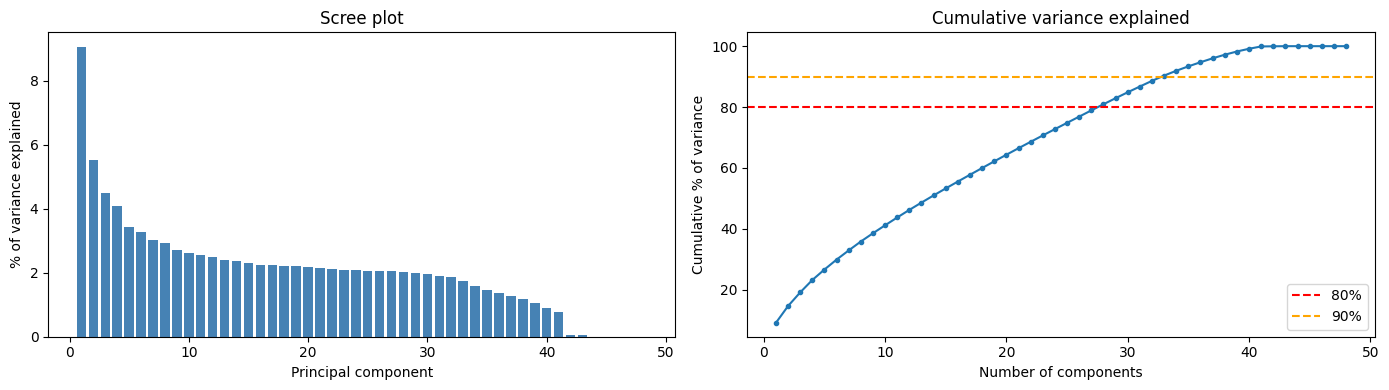

In [59]:
# Scree plot and cumulative variance plot
# Scree plot and cumulative variance plot
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].bar(range(1, len(var) + 1), var * 100, color="steelblue")
axes[0].set(title="Scree plot", xlabel="Principal component",
            ylabel="% of variance explained")

axes[1].plot(range(1, len(cum) + 1), cum * 100, marker="o", ms=3)
axes[1].axhline(80, color="red", ls="--", label="80%")
axes[1].axhline(90, color="orange", ls="--", label="90%")
axes[1].set(title="Cumulative variance explained", xlabel="Number of components",
            ylabel="Cumulative % of variance")
axes[1].legend()
plt.tight_layout(); plt.show()

Interpretation:

To keep 80% of the information (variance), PCA needs 28 components out of 48 columns. To keep 90%, it needs 33. I went with 80% and 28 components, which cuts the columns by about 40% but still keeps most of the information. PC1 carries the most information (about 9%) and PC2 comes next (about 5.5%). After the first four components the bars drop a little, and then each component adds only about 2–3%. This is because most of my columns are one-hot 0/1 columns that don’t have much to do with each other, so each one adds a small bit of new information. The last few components add almost nothing, which means some columns repeat information. In each one-hot group, you can always work out one column from the others. Also, age_group and has_capital_gain repeat what age and capital_gain already show.

## D4. Interpret the components
Loadings show how much each original column contributes to a component.
`

PC1
marital_status_Married-civ-spouse    0.41
relationship_Husband                 0.41
marital_status_Never-married        -0.35
age                                  0.30
age_group                            0.29
sex                                  0.25

PC2
age                        0.35
age_group                  0.34
marital_status_Divorced    0.31
sex                       -0.30
relationship_Unmarried     0.29
marital_status_Widowed     0.23

PC3
race_White                   0.39
education_num                0.38
race_Black                  -0.30
occupation_Prof-specialty    0.27
workclass_Private           -0.25
native_country               0.25



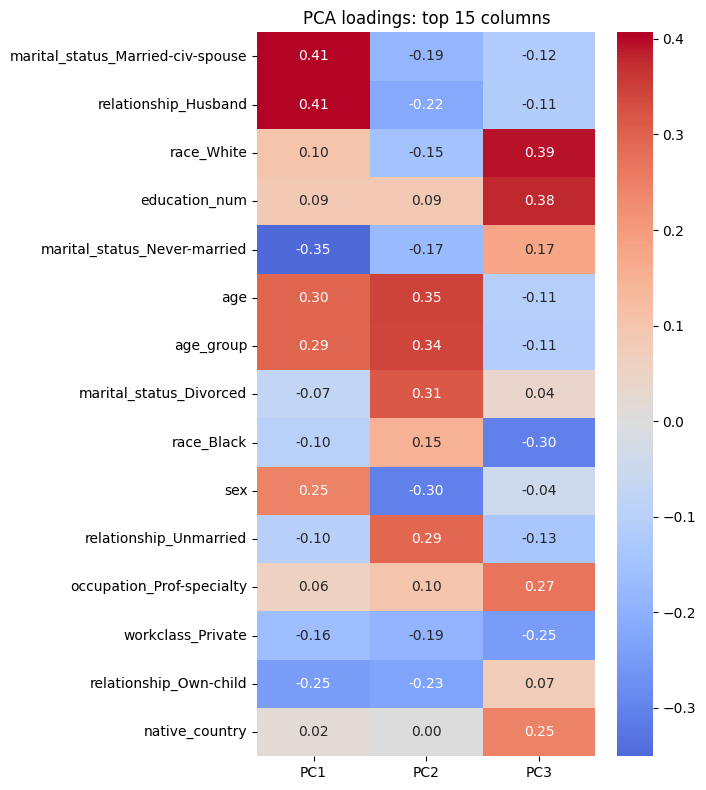

In [60]:
# Loadings: how much each original column contributes to PC1, PC2 and PC3
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns,
                        columns=["PC1", "PC2", "PC3"])

# Top 6 columns for each component (largest absolute loading)
for pc in ["PC1", "PC2", "PC3"]:
    top = loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(6)
    print(pc)
    print(top.round(2).to_string())
    print()

    # Heatmap of loadings for the 15 most important columns
top_cols = loadings.abs().max(axis=1).sort_values(ascending=False).head(15).index
plt.figure(figsize=(7, 8))
sns.heatmap(loadings.loc[top_cols], annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("PCA loadings: top 15 columns")
plt.tight_layout(); plt.show()

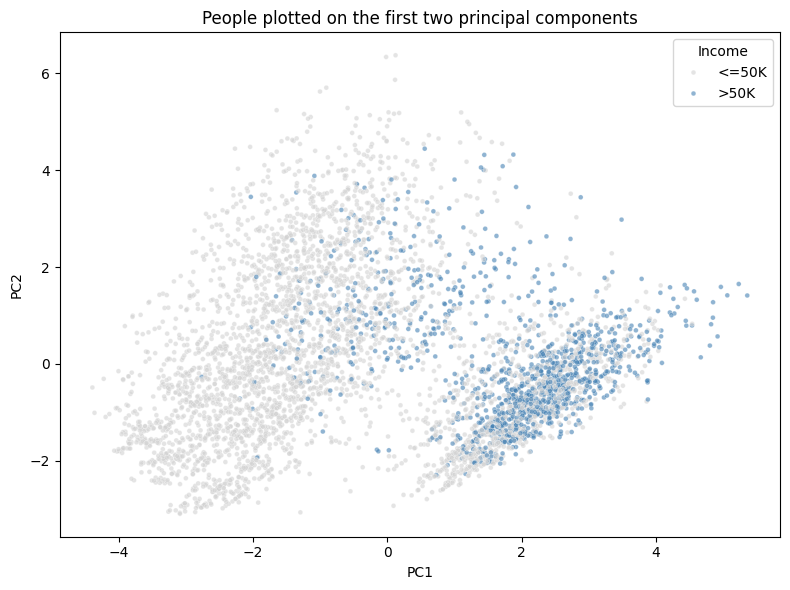

In [61]:
# PC1 vs PC2 for a random sample of 5,000 people, coloured by income
pcs = PCA(n_components=2).fit_transform(X_scaled)
idx = np.random.default_rng(42).choice(len(pcs), 5000, replace=False)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=pcs[idx, 0], y=pcs[idx, 1],
                hue=y.iloc[idx].map({0: "<=50K", 1: ">50K"}),
                palette={"<=50K": "lightgray", ">50K": "steelblue"}, alpha=0.6, s=12)
plt.title("People plotted on the first two principal components")
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.legend(title="Income"); plt.tight_layout(); plt.show()

Interpretation:

PC1 is mostly about life stage and household role. Married people, husbands, older people and men score high on PC1. Never-married people and young people still living with their parents (“own-child”) score low. So PC1 runs from young single people to older married men. This matches the EDA in Part C, where married people, husbands, older people and men had the highest share earning more than $50K.

PC2 is about older people who live without a spouse. Divorced, widowed and unmarried people score high, and because sex is negative here, they are more often women.

PC3 combines education, job type and background. People with more education, professional jobs, White people and those born in the US score high, while Black people and private-sector workers score lower.

In the scatter plot, people earning more than $50K (blue dots) are mostly on the right side of PC1, but they still overlap with the grey dots. This means PC1 (marriage, age and sex) is linked to higher income, but it does not fully separate high and low earners on its own.

Overall, PCA shows that the main patterns in the data come from marriage, age, sex, education and race, which are the same factors linked to income inequality in Part C.

## D5. Discussion
Dimensionality reduction vs feature selection: With feature selection, you pick which original columns to keep and drop the others. I did this in Part B when I removed fnlwgt and education. PCA works differently. It doesn’t throw away any columns. It makes new columns, called principal components, and each one is a mix of all the original columns.

Result: PCA brought the data down from 48 columns to 28 components and still kept 80% of the information (variance).

Limitations: PCA can only pick up straight-line patterns in the data. A lot of my columns are one-hot 0/1 columns, and PCA works better with normal numbers. Also, the new components are harder to understand than the original columns like age or education, because each one is a mix of many columns.